# Data-exploratie: M5 Forecasting (Walmart)

Wat zit er in de dataset, wat is er stuk aan, en wat heb ik eraan gedaan?
De code die het project draait, staat in `src/`. Deze notebook is alleen de verkenning
die tot de keuzes in `src/prepare.py` en `src/schema.py` geleid heeft.

Draai eerst de bestanden van Kaggle naar `data/` (zie README). Deze notebook leest de ruwe bestanden.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

DATA = Path("..") / "data"
verkoop = pd.read_csv(DATA / "sales_train_evaluation.csv")
kalender = pd.read_csv(DATA / "calendar.csv", parse_dates=["date"])
prijzen = pd.read_csv(DATA / "sell_prices.csv")
dagen = [c for c in verkoop.columns if c.startswith("d_")]
print("verkoop ", verkoop.shape, "->", len(dagen), "dagen")
print(
    "kalender", kalender.shape, kalender["date"].min().date(), "tot", kalender["date"].max().date()
)
print("prijzen ", prijzen.shape)

verkoop  (30490, 1947) -> 1941 dagen
kalender (1969, 14) 2011-01-29 tot 2016-06-19
prijzen  (6841121, 4)


## 1. Wat zit erin

- **sales_train_evaluation.csv**: 30.490 reeksen (product × winkel), 3 categorieën, 10 winkels in
  3 staten. Eén kolom per dag: `d_1` tot `d_1941`. Dat is een **breed** formaat.
- **calendar.csv**: per dag de datum, weekdag, events en of er SNAP is (voedselhulp in de VS).
- **sell_prices.csv**: verkoopprijs per product, winkel en **week** (`wm_yr_wk`), niet per dag.

In [2]:
print(verkoop.groupby("cat_id").size())
print(verkoop["store_id"].unique())
verkoop.iloc[:3, :10]

cat_id
FOODS        14370
HOBBIES       5650
HOUSEHOLD    10470
dtype: int64
<StringArray>
['CA_1', 'CA_2', 'CA_3', 'CA_4', 'TX_1', 'TX_2', 'TX_3', 'WI_1', 'WI_2',
 'WI_3']
Length: 10, dtype: str


,id,item_id,dept_id,cat_id,store_id,state_id,d_1,d_2,d_3,d_4
0,HOBBIES_1_001_CA_1_evaluation,HOBBIES_1_001,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
1,HOBBIES_1_002_CA_1_evaluation,HOBBIES_1_002,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0
2,HOBBIES_1_003_CA_1_evaluation,HOBBIES_1_003,HOBBIES_1,HOBBIES,CA_1,CA,0,0,0,0


## 2. Twee bestanden die ik niet gebruik

- `sales_train_validation.csv` is **dezelfde** data als `evaluation`, alleen 28 dagen korter.
  Beide inlezen zou dubbel tellen. Ik gebruik alleen `evaluation`.
- `sample_submission.csv` is het formaat om in te dienen op Kaggle. Het bevat geen data.

In [3]:
val = pd.read_csv(DATA / "sales_train_validation.csv", usecols=["id", "d_1913"])
zelfde = (
    val["id"].str.replace("_validation", "") == verkoop["id"].str.replace("_evaluation", "")
).all()
print(
    "zelfde reeksen:",
    zelfde,
    "| zelfde verkoop op d_1913:",
    (val["d_1913"] == verkoop["d_1913"]).all(),
)
print(
    "kalender heeft",
    len(kalender) - len(dagen),
    "dagen zonder verkoop (de toekomst van de wedstrijd)",
)

zelfde reeksen: True | zelfde verkoop op d_1913: True
kalender heeft 28 dagen zonder verkoop (de toekomst van de wedstrijd)


## 3. Te groot en te breed: een subset

Alles in lang formaat is 30.490 × 1941 ≈ 59 miljoen rijen, en de ruwe bestanden zijn groter dan
de limiet van 100 MB op GitHub. Mijn use-case is voeding, dus ik neem **één winkel (CA_1), één
voedingsdepartement (FOODS_3)** en de **laatste twee jaar**.

Probleem: in FOODS_3 verkoopt bijna de helft van de product-dagen **niets**. Voor een eerste model kies ik
de **50 best verkopende producten**. Daar zakt het aandeel nullen naar ongeveer 15%. Die selectie
gebeurt op de trainingsperiode, niet op de testdagen.

In [4]:
f = verkoop[(verkoop["store_id"] == "CA_1") & (verkoop["dept_id"] == "FOODS_3")].set_index(
    "item_id"
)
laatste = dagen[-730:]
top = f[laatste[:-28]].sum(axis=1).nlargest(50).index
print("producten in CA_1 FOODS_3:", len(f))
print(f"nullen, alle producten:  {(f[laatste] == 0).to_numpy().mean():.0%}")
print(f"nullen, top 50:          {(f.loc[top, laatste] == 0).to_numpy().mean():.0%}")

producten in CA_1 FOODS_3: 823
nullen, alle producten:  45%
nullen, top 50:          15%


## 4. Wat er stuk is

### 4a. Gesloten dagen
Elke kerstdag verkoopt het hele departement **0 stuks**: de winkel is dicht. Dat is geen lage vraag.
Zoals in mijn voorstel tellen die dagen niet mee: `prepare.py` gooit ze weg.

dagen met 0 verkoop: [datetime.date(2011, 12, 25), datetime.date(2012, 12, 25), datetime.date(2013, 12, 25), datetime.date(2014, 12, 25), datetime.date(2015, 12, 25)]


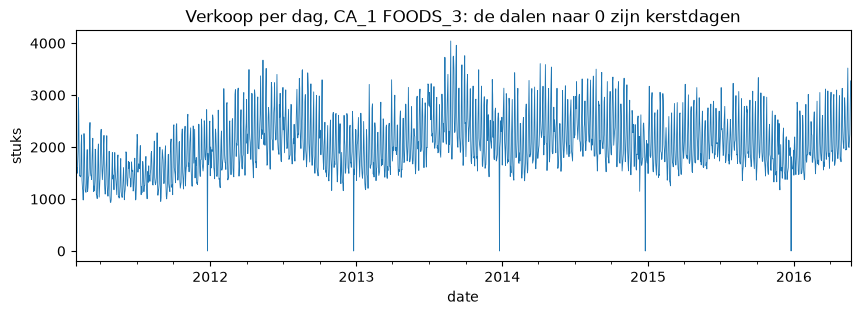

In [5]:
per_dag = f[dagen].sum()
per_dag.index = kalender.set_index("d").loc[dagen, "date"]
print("dagen met 0 verkoop:", [d.date() for d in per_dag[per_dag == 0].index])

fig, ax = plt.subplots(figsize=(10, 3))
per_dag.plot(ax=ax, lw=0.6)
ax.set_title("Verkoop per dag, CA_1 FOODS_3: de dalen naar 0 zijn kerstdagen")
ax.set_ylabel("stuks")
plt.show()

### 4b. Producten die later in het assortiment komen
Bijna de helft van de producten verkoopt de eerste 100 dagen niets: ze lagen nog niet in de winkel.
Die dagen hebben **geen prijs**. Een nul is daar geen "niet verkocht" maar "niet te koop".
`prepare.py` laat rijen zonder prijs vallen.

In [6]:
eerste_verkoop = (f[dagen] > 0).to_numpy().argmax(axis=1)
print(
    "producten die pas na d_100 voor het eerst verkopen:",
    (eerste_verkoop > 100).sum(),
    "van",
    len(f),
)
p = prijzen[(prijzen["store_id"] == "CA_1") & prijzen["item_id"].isin(f.index)]
print(
    "weken met een prijs per product: min",
    p.groupby("item_id").size().min(),
    "max",
    p.groupby("item_id").size().max(),
)

producten die pas na d_100 voor het eerst verkopen: 395 van 823


weken met een prijs per product: min 19 max 282


### 4c. Events zijn bijna altijd leeg
`event_type_1` is leeg op 1807 van de 1969 dagen. Leeg betekent hier "geen event", geen ontbrekende
waarde. Ik vul het op met `"geen"`. `event_type_2` is maar 5 keer ingevuld: die laat ik weg.

In [7]:
print(kalender["event_type_1"].value_counts(dropna=False))
print("event_type_2 ingevuld:", kalender["event_type_2"].notna().sum())

event_type_1
NaN          1807
Religious      55
National       52
Cultural       37
Sporting       18
Name: count, dtype: int64
event_type_2 ingevuld: 5


### 4d. Prijzen: welk bereik is geloofwaardig?
Voeding in CA_1 kost tussen 0,20 en 20 dollar. Het schema laat 0,01 tot 50 toe. Een prijs in **cent**
(×100) valt daar meteen buiten, en dat is precies de stille fout die een nieuw kassasysteem kan maken.

In [8]:
print(p["sell_price"].describe().round(2))

count    186763.00
mean          2.86
std           1.76
min           0.20
25%           1.98
50%           2.50
75%           3.58
max          19.48
Name: sell_price, dtype: float64


## 5. Patronen: wat kan een model leren?

Er is een duidelijk **weekpatroon** (het weekend verkoopt meer) en een klein effect van **SNAP-dagen** (ongeveer 5% meer).
Daarom zitten weekdag, SNAP en de verkoop van **vorige week** in de features. "Zelfde als vorige
week" is meteen ook mijn baseline.

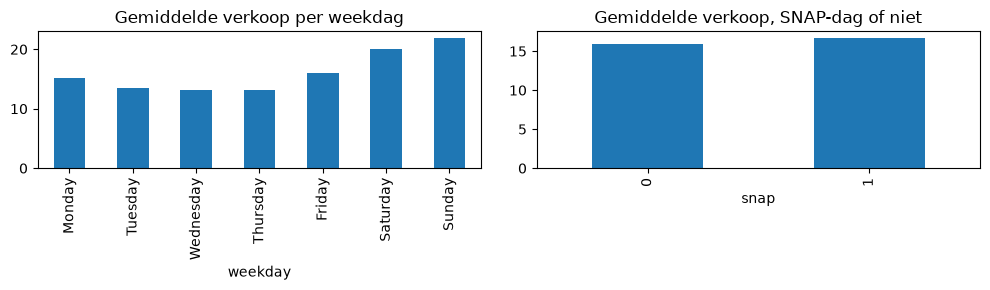

correlatie verkoop met lag_7: 0.71 | met lag_1: 0.76


In [9]:
sub = pd.read_csv(DATA / "m5_subset.csv")
fig, ax = plt.subplots(1, 2, figsize=(10, 3))
volgorde = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]
sub.groupby("weekday")["sales"].mean().reindex(volgorde).plot.bar(
    ax=ax[0], title="Gemiddelde verkoop per weekdag"
)
sub.groupby("snap")["sales"].mean().plot.bar(ax=ax[1], title="Gemiddelde verkoop, SNAP-dag of niet")
plt.tight_layout()
plt.show()
print(
    "correlatie verkoop met lag_7:",
    sub["sales"].corr(sub["lag_7"]).round(2),
    "| met lag_1:",
    sub["sales"].corr(sub["lag_1"]).round(2),
)

## 6. Samenvatting: probleem en oplossing

| Probleem | Wat ik eraan deed | Waar |
|---|---|---|
| Breed formaat, één kolom per dag | `melt` naar één rij per product per dag | `prepare.py` |
| Te groot voor git en voor snelle tests | subset: CA_1, FOODS_3, top 50, laatste 2 jaar | `configs/default.yaml` |
| `validation` = `evaluation` min 28 dagen | alleen `evaluation` gebruikt | `configs/default.yaml` |
| Kerstdag: winkel gesloten, 0 verkoop | die dagen weggelaten | `prepare.py` |
| Product nog niet in het assortiment | rijen zonder prijs weggelaten | `prepare.py` |
| Events bijna altijd leeg | `"geen"` ingevuld, `event_type_2` weggelaten | `prepare.py` |
| Prijzen per week, verkoop per dag | koppelen via `wm_yr_wk` | `prepare.py` |
| Stille eenheidsfout (cent) | bereik 0,01–50 in het schema | `schema.py` |
| **Leakage**: features van de dag zelf | lags en gemiddelden altijd met `shift`, getest | `prepare.py`, `test_data.py` |
| **Leakage**: willekeurige split | tijdsplit: laatste 28 dagen zijn test, getest | `train.py`, `test_model.py` |

Wat de data **niet** heeft: inkoopprijzen, weerdata en voorraad. Daardoor is verkoop niet hetzelfde
als vraag: als een product op is, toont de kassa minder dan wat klanten wilden kopen.